In [36]:
import sys, pickle
from pathlib import Path
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
G = pickle.load(open(ROOT / "data" / "processed" / "nordic_graph.pkl", "rb"))

In [37]:
from src.metrics import betweenness, centralization
bc = betweenness(G)
CENTRALIZATION_V1 = centralization(bc)
print(f"Betweenness centralization: {CENTRALIZATION_V1:.4f}")

Betweenness centralization: 0.3010


In [38]:
# Nodes, edges, density, components
N, E = G.number_of_nodes(), G.number_of_edges()
print(f"nodes={N}  edges={E}  density={nx.density(G):.6f}")
print("components:", nx.number_connected_components(G))
print("avg degree:", 2*E/N)
strength = dict(G.degree(weight="capacity"))
print("avg strength (MVA):", np.mean(list(strength.values())))

nodes=1763  edges=2253  density=0.001451
components: 1
avg degree: 2.5558706749858198
avg strength (MVA): 5821.540150879184


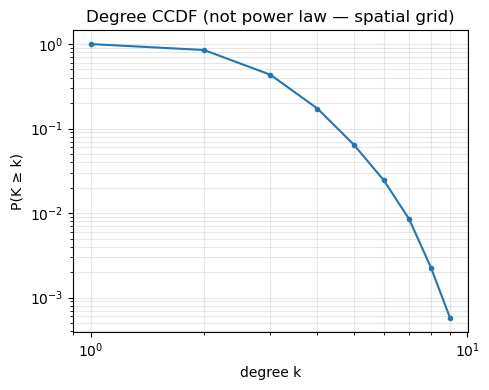

In [39]:
#log log
import matplotlib.pyplot as plt

degrees = np.array([d for _, d in G.degree()])
ks = np.arange(degrees.min(), degrees.max() + 1)
ccdf = [(degrees >= k).mean() for k in ks]

fig, ax = plt.subplots(figsize=(5, 4))
ax.loglog(ks, ccdf, "o-", ms=3)
ax.set_xlabel("degree k")
ax.set_ylabel("P(K ≥ k)")
ax.set_title("Degree CCDF (not power law — spatial grid)")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig(ROOT / "results" / "figures" / "degree_ccdf.png", dpi=200)
plt.show()

In [40]:
gc = nx.transitivity(G)                    # global
ac = nx.average_clustering(G)              # average
print(f"global clustering = {gc:.4f}")
print(f"average clustering = {ac:.4f}")
print(f"global > average? {gc > ac}")

global clustering = 0.0526
average clustering = 0.0451
global > average? True


In [ ]:
# average path length and diameter (hops AND km)
import networkx as nx
import numpy as np

avg_hops  = nx.average_shortest_path_length(G)
diam_hops = nx.diameter(G)
print(f"avg path (hops): {avg_hops:.2f}")
print(f"diameter (hops): {diam_hops}")

G_len = nx.Graph()
G_len.add_nodes_from(G)
FLOOR_M = 1.0  # 1 metre, avoids zero/negative weights that break Dijkstra
for u, v, d in G.edges(data=True):
    L = d.get("length")
    L_km = (float(L) / 1000.0) if (L is not None and float(L) > 0) else FLOOR_M / 1000.0
    G_len.add_edge(u, v, length=L_km)

avg_km  = nx.average_shortest_path_length(G_len, weight="length")
diam_km = nx.diameter(G_len, weight="length")
print(f"avg path (km): {avg_km:.1f}")
print(f"diameter (km): {diam_km:.1f}")

avg path (hops): 24.65
diameter (hops): 64
avg path (km): 1144.3
diameter (km): 3419.5


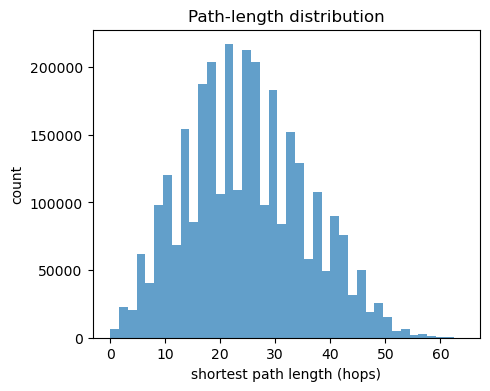

In [ ]:
#avg path length distribution
import collections
hops = []
for src in G:
    lengths = nx.single_source_shortest_path_length(G, src)
    hops.extend(lengths.values())
fig, ax = plt.subplots(figsize=(5, 4))
ax.hist(hops, bins=40, alpha=0.7)
ax.set_xlabel("shortest path length (hops)")
ax.set_ylabel("count")
ax.set_title("Path-length distribution")
plt.savefig(ROOT / "results" / "figures" / "path_lengths.png", dpi=200)
plt.show()

In [43]:
#assortativity
print("degree assortativity:", nx.degree_assortativity_coefficient(G))
print("voltage assortativity:", nx.numeric_assortativity_coefficient(G, "voltage"))

degree assortativity: 0.0058536698927433494
voltage assortativity: 0.7608226372190013


In [ ]:
#top10 candidate
bc = nx.betweenness_centrality(G, weight="cost", normalized=True)
top = sorted(bc.items(), key=lambda x: -x[1])[:10]
df_top = pd.DataFrame([
    {"bus": n, "country": G.nodes[n]["country"],
     "voltage": G.nodes[n]["voltage"], "betweenness": b}
    for n, b in top
])
print(df_top.to_string(index=False))

                 bus country  voltage  betweenness
    way/29309786-380      DE      380     0.315637
    way/27739871-380      DE      380     0.271180
   way/525964629-380      DE      380     0.267298
relation/8890887-420      NO      420     0.267218
       way/525964617      DE      525     0.265442
    relation/8890887      NO      525     0.265098
            DE11-380      DE      380     0.261920
   way/955268863-380      DE      380     0.251336
            DE10-380      DE      380     0.231482
             DE8-380      DE      380     0.230715


In [45]:
import networkx as nx

# Degree assortativity: do high-degree nodes connect to high-degree nodes?
deg_assort = nx.degree_assortativity_coefficient(G)

volt_assort = nx.numeric_assortativity_coefficient(G, "voltage")

print(f"degree assortativity  = {deg_assort:+.4f}")
print(f"voltage assortativity = {volt_assort:+.4f}")

degree assortativity  = +0.0059
voltage assortativity = +0.7608


In [46]:
import pandas as pd

rows = [{
    "bus": n,
    "country": d.get("country"),
    "voltage": pd.to_numeric(d.get("voltage"), errors="coerce"),
    "is_dc": str(d.get("dc", "f")).lower() in ("t", "true", "1"),
    "betweenness": bc[n],
    "degree": G.degree(n),
} for n, d in G.nodes(data=True)]
df = pd.DataFrame(rows)

#  380 kV+ AC substations (not DC converter endpoints)
ac = df[(df.voltage >= 380) & (~df.is_dc)].copy()
print(f"380 kV+ AC substations: {len(ac)}")
print(ac.country.value_counts().to_string())

380 kV+ AC substations: 894
country
DE    446
NO    136
SE    104
PL     86
FI     79
DK     42
LT      1


In [47]:
harm = nx.harmonic_centrality(G, distance="cost")

top = sorted(bc.items(), key=lambda x: -x[1])[:10]
df_top = pd.DataFrame([
    {"bus": n,
     "country": G.nodes[n]["country"],
     "voltage": G.nodes[n]["voltage"],
     "degree": G.degree(n),
     "strength": strength[n],
     "betweenness": bc[n],
     "harmonic": harm[n]}
    for n, _ in top
])
print(df_top.to_string(index=False))

                 bus country  voltage  degree  strength  betweenness      harmonic
    way/29309786-380      DE      380       5 13584.824     0.315637 358754.072061
    way/27739871-380      DE      380       4 18679.719     0.271180 338262.410359
   way/525964629-380      DE      380       4 14984.821     0.267298 304546.304994
relation/8890887-420      NO      420       5 16415.400     0.267218 253734.585520
       way/525964617      DE      525       2  2800.000     0.265442 259474.147758
    relation/8890887      NO      525       2  2800.000     0.265098 244655.810735
            DE11-380      DE      380       3 16981.025     0.261920 335001.599760
   way/955268863-380      DE      380       4 16981.616     0.251336 332145.599650
            DE10-380      DE      380       3 20377.230     0.231482 330014.108245
             DE8-380      DE      380       3 13584.820     0.230715 319973.919809


In [48]:
ebc = nx.edge_betweenness_centrality(G, weight="cost", normalized=True)
top_edges = sorted(ebc.items(), key=lambda x: -x[1])[:10]

df_edges = pd.DataFrame([
    {"u": u, "v": v,
     "u_country": G.nodes[u]["country"],
     "v_country": G.nodes[v]["country"],
     "u_voltage": G.nodes[u]["voltage"],
     "v_voltage": G.nodes[v]["voltage"],
     "edge_betweenness": b}
    for (u, v), b in top_edges
])
print(df_edges.to_string(index=False))

                u                    v u_country v_country  u_voltage  v_voltage  edge_betweenness
way/525964629-380        way/525964617        DE        DE        380        525          0.265883
 relation/8890887        way/525964617        NO        DE        525        525          0.265532
 relation/8890887 relation/8890887-420        NO        NO        525        420          0.265197
way/955268863-380     way/27739871-380        DE        DE        380        380          0.249698
         DE11-380    way/955268863-380        DE        DE        380        380          0.248622
         DE10-380             DE11-380        DE        DE        380        380          0.231520
         DE10-380              DE8-380        DE        DE        380        380          0.230919
          DE6-380    way/525964629-380        DE        DE        380        380          0.201354
          DE8-380   way/1107961833-380        DE        DE        380        380          0.200679
          

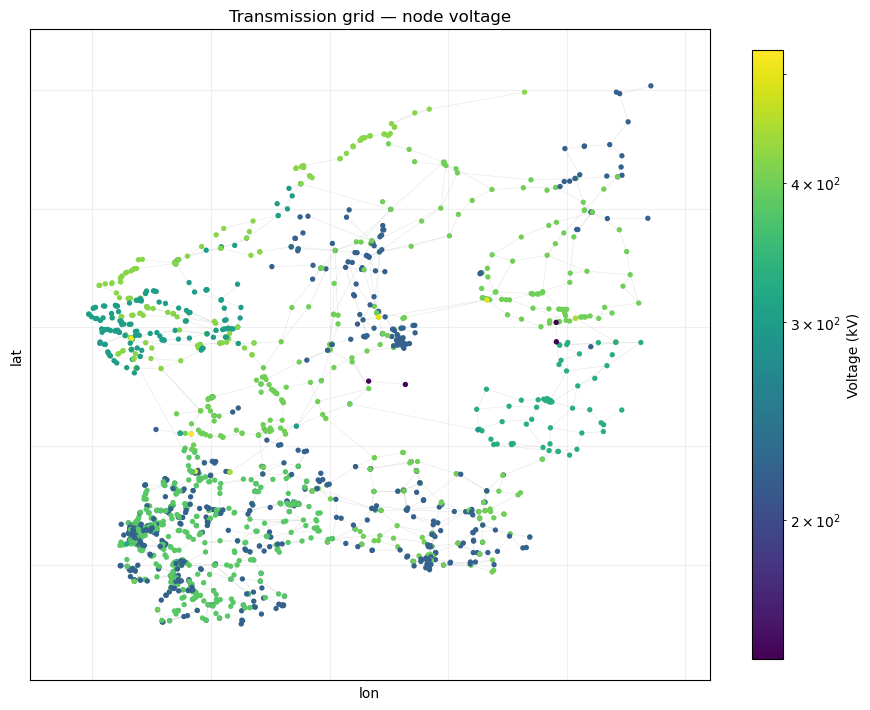

In [49]:
import matplotlib.colors as mcolors

voltages = np.array([G.nodes[n]["voltage"] for n in G], dtype=float)
xs = np.array([pos[n][0] for n in G])
ys = np.array([pos[n][1] for n in G])

fig, ax = plt.subplots(figsize=(9, 9))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="lightgray", width=0.4, alpha=0.6)
sc = ax.scatter(xs, ys, c=voltages, s=8, cmap="viridis",
                norm=mcolors.LogNorm(vmin=max(voltages.min(), 1), vmax=voltages.max()),
                zorder=3)
plt.colorbar(sc, ax=ax, shrink=0.7, label="Voltage (kV)")
ax.set_title("Transmission grid — node voltage")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig(ROOT / "results" / "figures" / "voltage_map.png", dpi=200)
plt.show()

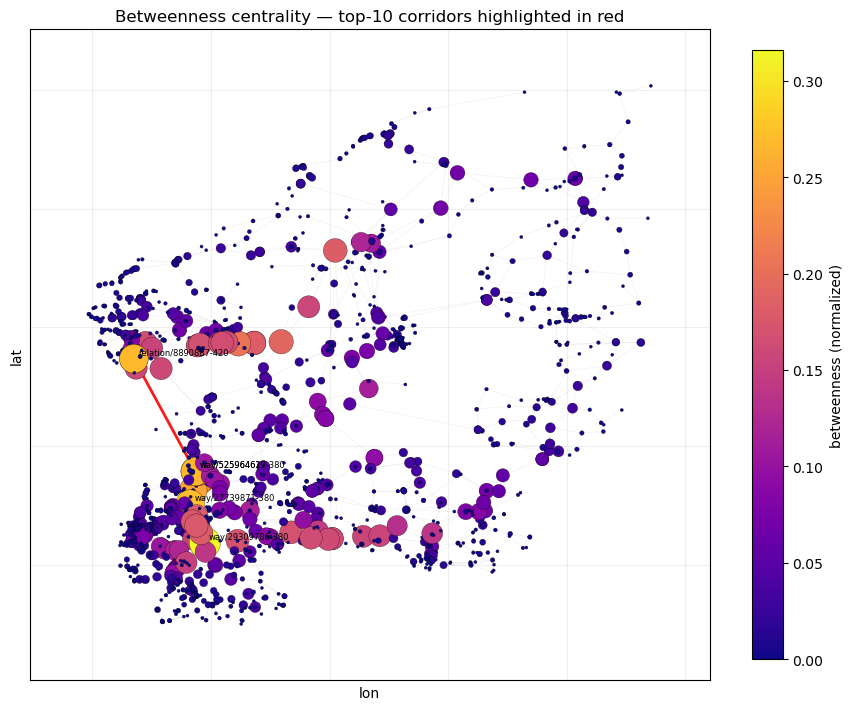

In [50]:
bc_vals = np.array([bc[n] for n in G])
sizes = 5 + 500 * (bc_vals / bc_vals.max())

fig, ax = plt.subplots(figsize=(9, 9))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="lightgray", width=0.3, alpha=0.5)
nx.draw_networkx_edges(G, pos, edgelist=[e for e, _ in top_edges], ax=ax,
                       edge_color="red", width=2.0, alpha=0.9)
sc = ax.scatter(xs, ys, s=sizes, c=bc_vals, cmap="plasma",
                edgecolors="black", linewidths=0.2, zorder=3)
plt.colorbar(sc, ax=ax, shrink=0.7, label="betweenness (normalized)")
for n, _ in top[:5]:
    ax.annotate(n, pos[n], fontsize=6, xytext=(3, 3),
                textcoords="offset points", zorder=4)
ax.set_title("Betweenness centrality — top-10 corridors highlighted in red")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig(ROOT / "results" / "figures" / "betweenness_map.png", dpi=200)
plt.show()

             degree  strength  betweenness  harmonic
degree        1.000     0.659        0.608     0.349
strength      0.659     1.000        0.664     0.600
betweenness   0.608     0.664        1.000     0.355
harmonic      0.349     0.600        0.355     1.000


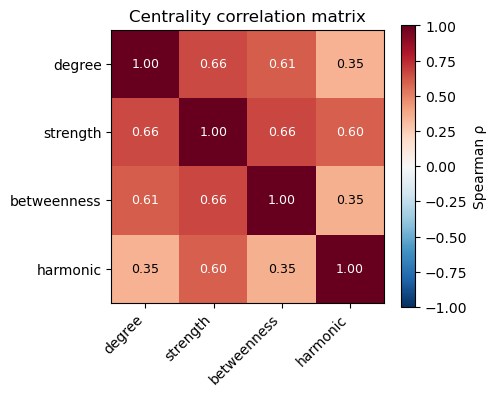

In [51]:
from scipy.stats import spearmanr

df_cent = pd.DataFrame({
    "degree":      [G.degree(n) for n in G],
    "strength":    [strength[n] for n in G],
    "betweenness": [bc[n] for n in G],
    "harmonic":    [harm[n] for n in G],
}, index=list(G.nodes()))

corr, _ = spearmanr(df_cent)
df_corr = pd.DataFrame(corr, index=df_cent.columns, columns=df_cent.columns)
print(df_corr.round(3).to_string())

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(df_corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(df_corr))); ax.set_yticks(range(len(df_corr)))
ax.set_xticklabels(df_corr.columns, rotation=45, ha="right")
ax.set_yticklabels(df_corr.columns)
for i in range(len(df_corr)):
    for j in range(len(df_corr)):
        ax.text(j, i, f"{df_corr.values[i, j]:.2f}",
                ha="center", va="center",
                color="white" if abs(df_corr.values[i, j]) > 0.6 else "black",
                fontsize=9)
plt.colorbar(im, ax=ax, label="Spearman ρ", shrink=0.8)
ax.set_title("Centrality correlation matrix")
plt.tight_layout()
plt.savefig(ROOT / "results" / "figures" / "centrality_corr.png", dpi=200)
plt.show()

In [52]:
stats = pd.DataFrame([
    ("nodes",             G.number_of_nodes()),
    ("edges",             G.number_of_edges()),
    ("density",           nx.density(G)),
    ("components",        nx.number_connected_components(G)),
    ("avg_degree",        2 * G.number_of_edges() / G.number_of_nodes()),
    ("avg_strength_MVA",  float(np.mean(list(strength.values())))),
    ("global_clustering", nx.transitivity(G)),
    ("avg_clustering",    nx.average_clustering(G)),
    ("avg_path_hops",     avg_hops),
    ("diameter_hops",     diam_hops),
    ("avg_path_km",       avg_km),
    ("diameter_km",       diam_km),
    ("degree_assort",     deg_assort),
    ("voltage_assort",    volt_assort),
    ("betweenness_centralization", CENTRALIZATION_V1),
], columns=["metric", "value"])

stats.to_csv(ROOT / "results" / "eda_stats.csv", index=False)
print(stats.to_string(index=False))

                    metric       value
                     nodes 1763.000000
                     edges 2253.000000
                   density    0.001451
                components    1.000000
                avg_degree    2.555871
          avg_strength_MVA 5821.540151
         global_clustering    0.052620
            avg_clustering    0.045090
             avg_path_hops   24.652402
             diameter_hops   64.000000
               avg_path_km 1144.272253
               diameter_km 3419.482430
             degree_assort    0.005854
            voltage_assort    0.760823
betweenness_centralization    0.301039


In [53]:
rows = [{
    "bus": n,
    "country": d.get("country"),
    "voltage": pd.to_numeric(d.get("voltage"), errors="coerce"),
    "is_dc": str(d.get("dc", "f")).lower() in ("t", "true", "1"),
    "betweenness": bc[n],
    "degree": G.degree(n),
} for n, d in G.nodes(data=True)]
df = pd.DataFrame(rows)
ac = df[(df.voltage >= 380) & (~df.is_dc)].copy()
print(f"380 kV+ AC substations: {len(ac)}")

TARGET_COUNTRIES = ["DE", "NO", "SE", "FI"]
N_PER_COUNTRY    = 6

pool = ac[ac.country.isin(TARGET_COUNTRIES)].sort_values("betweenness")

selected = (
    pool.groupby("country", group_keys=False)[["bus", "country", "voltage", "betweenness"]]
        .apply(lambda d: pd.concat([d.head(N_PER_COUNTRY // 2),
                                    d.tail(N_PER_COUNTRY // 2)]))
        .drop_duplicates(subset="bus")
        .reset_index(drop=True)
)

selected.to_csv(ROOT / "results" / "candidates.csv", index=False)
print(f"Wrote {len(selected)} candidates → results/candidates.csv")
print(selected.country.value_counts().to_string())

380 kV+ AC substations: 894
Wrote 24 candidates → results/candidates.csv
country
DE    6
FI    6
NO    6
SE    6
